Original Dataset:
    Haemoglobin       RBC     Glucose  Cholesterol        BMI
0    13.745071  5.014672   78.111447   212.709658  28.753135
1    12.792604  5.136471   98.012500   162.335040  22.935821
2    13.971533  5.449831  110.104874   216.088178  25.384483
3    15.284545  5.432281  110.939612   230.669136  23.150899
4    12.648770  3.973398  100.998691   202.403047  23.262015

Covariance Matrix:
              Haemoglobin       RBC   Glucose  Cholesterol       BMI
Haemoglobin     1.000000  0.095147 -0.134197     0.065398 -0.031206
RBC             0.095147  1.000000 -0.032626    -0.101396 -0.142037
Glucose        -0.134197 -0.032626  1.000000     0.105959  0.025853
Cholesterol     0.065398 -0.101396  0.105959     1.000000  0.171162
BMI            -0.031206 -0.142037  0.025853     0.171162  1.000000

Correlation Matrix:
              Haemoglobin       RBC   Glucose  Cholesterol       BMI
Haemoglobin     1.000000  0.095147 -0.134197     0.065398 -0.031206
RBC             0.095147  1.

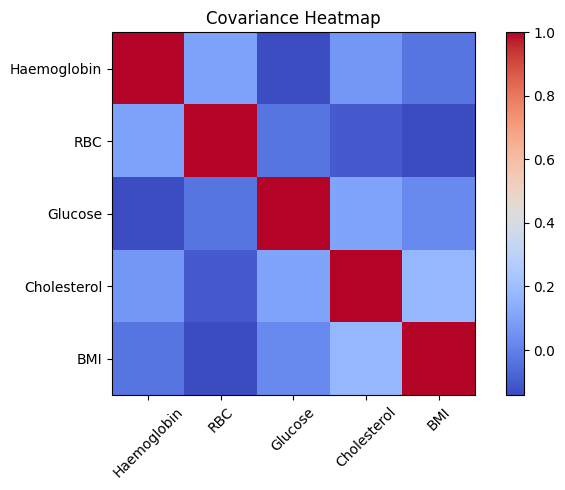

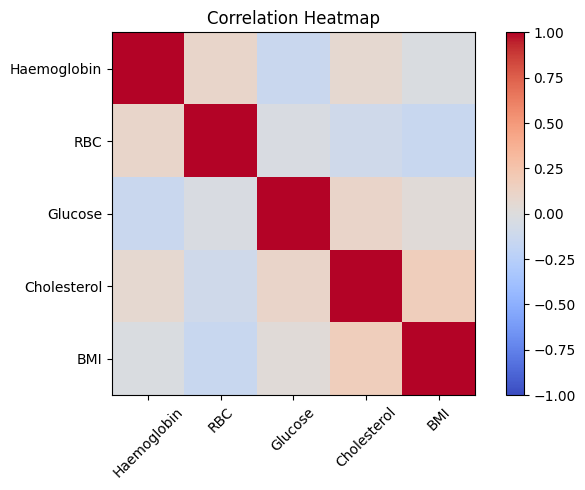


Eigenvalues:
 [1.32511405 1.11031401 0.9828869  0.83771742 0.74396762]

Eigenvectors:
 [[ 0.24613228 -0.74067287  0.23509617  0.26622328  0.51446823]
 [ 0.50426715 -0.0331167   0.53660467 -0.64546125 -0.20013277]
 [-0.36174773  0.45018115  0.66229107  0.10017661  0.46670193]
 [-0.51080366 -0.41117874  0.4104134   0.15383577 -0.61474145]
 [-0.54161955 -0.28031404 -0.2229722  -0.69195675  0.31551793]]

Variance Percentage:
 [26.50228096 22.20628013 19.65773808 16.7543484  14.87935244]


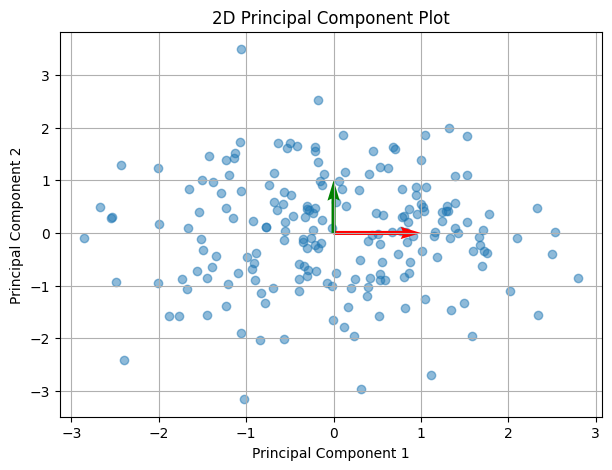


First Two Components Capture: 48.71 %


In [3]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Generate dataset of 200 patients
np.random.seed(42)
data = pd.DataFrame({
    'Haemoglobin': np.random.normal(13, 1.5, 200),
    'RBC': np.random.normal(4.8, 0.6, 200),
    'Glucose': np.random.normal(110, 20, 200),
    'Cholesterol': np.random.normal(190, 30, 200),
    'BMI': np.random.normal(25, 4, 200)
})

print("Original Dataset:\n", data.head())

# 2. Standardise features
X = (data - data.mean()) / data.std()

# 3. Covariance and Correlation
cov = X.cov()
corr = X.corr()

print("\nCovariance Matrix:\n", cov)
print("\nCorrelation Matrix:\n", corr)

# 4. Plot heatmaps
plt.figure(figsize=(7,5))
plt.imshow(cov, cmap='coolwarm')
plt.colorbar()
plt.xticks(range(5), data.columns, rotation=45)
plt.yticks(range(5), data.columns)
plt.title("Covariance Heatmap")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7,5))
plt.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(5), data.columns, rotation=45)
plt.yticks(range(5), data.columns)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

# 5. Eigenvalues and Eigenvectors
values, vectors = np.linalg.eigh(cov)
idx = np.argsort(values)[::-1]
values = values[idx]
vectors = vectors[:, idx]

print("\nEigenvalues:\n", values)
print("\nEigenvectors:\n", vectors)

# 6. Percentage of Variance
variance = values / values.sum() * 100
print("\nVariance Percentage:\n", variance)

# 7. Project data into 2D
pc = X.values @ vectors[:, :2]

plt.figure(figsize=(7,5))
plt.scatter(pc[:, 0], pc[:, 1], alpha=0.5)
plt.quiver(0, 0, 1, 0, angles='xy',
           scale_units='xy', scale=1, color='red')
plt.quiver(0, 0, 0, 1, angles='xy',
           scale_units='xy', scale=1, color='green')
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("2D Principal Component Plot")
plt.grid()
plt.show()

print("\nFirst Two Components Capture:",
      round(variance[:2].sum(), 2), "%")
